In [2]:
import matplotlib.pyplot as plt
from metric import LearnMetric
from reach import ReachEstimator
from manifold_func import *
from sklearn.preprocessing import StandardScaler
from sklearn import datasets
from skopt import gp_minimize
from functools import lru_cache
from skopt.space import Real, Integer
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
from scipy.optimize import minimize_scalar
import random
import datetime
import time

# Choosing Parameters

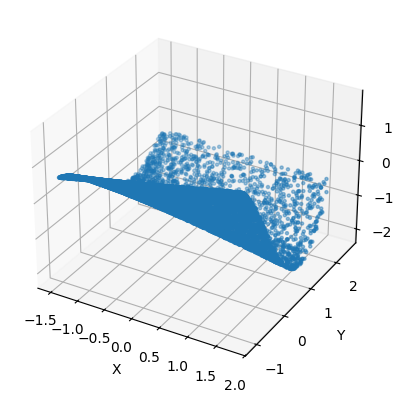

Input 10000 points, ambient dimension: 4, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 6
  Neighbors Radius = [0.09888825248594041, 0.9688208403410233]
2026-05-06 23:17:21.886430


In [5]:
np.random.seed(1)
n = 10000
# X = sample_sphere(10000,3)
# small_coord_sys, full_coord_sys = sample_manifold(torus(R=3, r=1.5))
# small_coord_sys, full_coord_sys = sample_manifold(swiss_roll())
# small_coord_sys, full_coord_sys = sample_m1()
small_coord_sys, full_coord_sys = sample_m2()
small_coord_sys.generate_data(num_samples=n)
X = small_coord_sys.data.amb_pts

# if manifold has with boundary, select inner points
inner = np.flatnonzero(np.abs(small_coord_sys.data.coord_pts).max(axis=1) < 0.8)

# X = directional_stretch(X, direction=np.array([1,0,0]), p = 2) 
X = StandardScaler().fit_transform(X)


fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:, 2], s=5)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.show()

metric = LearnMetric(X, 2)
T = metric.tangent_space(k = 100, degree = 6)

now = datetime.datetime.now()
print(now)

In [7]:
now = datetime.datetime.now()
print(now)

def f(x):
    eps, r = x
    
    # manifolds with boundary
    indices = random.sample(list(inner), len(inner))
    H = metric.distortion(epsilon = eps, radius = r, indices=indices)
    
    # manifolds without boundary
    # H = metric.distortion(T = T, epsilon = eps, radius = r)
    
    rmetric = np.sqrt(np.linalg.eigvalsh(H))
    err = np.max(np.abs(rmetric - 1)**2, axis=1)
    return np.mean(err)

space = [
    # Choose starting point depends on empirical validation
    Real(0.3, 0.8, name="a"),
    Real(0.3, 1, name="b")
]

res = gp_minimize(
    f,
    space,
    n_calls=60, 
    n_initial_points=10,
    acq_func="EI",
    random_state=0
)

x_max = res.x
f_max = res.fun
print(x_max,f_max)
now = datetime.datetime.now()
print(now)


2026-05-06 23:18:38.203294
[0.3006881815926802, 0.6788941049743745] 0.01178477175167674
2026-05-06 23:25:38.787993


In [9]:
eps, r = x_max

H = metric.distortion(epsilon = eps, radius = r, indices = inner)
rmetric = np.sqrt(np.linalg.svdvals(H))
err = np.max(np.abs(rmetric - 1), axis=1)

print(np.mean(err), np.min(err), np.max(err))

now = datetime.datetime.now()
print(now)

0.08217329577273176 0.0012024699865949007 0.3285704664888446
2026-05-06 23:26:37.809254


In [10]:
now = datetime.datetime.now()
print(now)

start = time.time()
metric._laplacian_eigenmap_without_t(L = metric.L, epsilon = eps, m = 100)
print(metric.vals)
end = time.time()

print("running time:", end - start)

now = datetime.datetime.now()
print(now)

2026-05-06 23:26:47.128014
[ 0.07331937  0.27509327  0.33410572  0.42757329  0.56744215  0.72024169
  0.94661214  1.21075952  1.44420453  1.49162072  1.54896387  1.78207824
  1.91717457  2.02008503  2.17452547  2.54150002  2.62121773  2.73582575
  3.23383573  3.26430383  3.32529175  3.44092897  3.47840061  3.63312108
  3.85368709  4.01823831  4.18316113  4.41530043  4.56881597  4.86770769
  4.92968374  5.02191065  5.31615674  5.38385893  5.4679997   5.50626167
  5.6475712   5.80393199  5.88023069  6.05650382  6.24918965  6.29274238
  6.37133147  6.44416476  6.63200148  6.81414816  7.01784998  7.08834155
  7.18102564  7.28979433  7.39209216  7.52048429  7.63486788  7.7310148
  7.74922882  7.81869759  7.85274592  7.94114184  8.06192268  8.15566989
  8.20391325  8.34958209  8.3800132   8.50546167  8.60268778  8.70916242
  8.79692295  8.84869684  8.91475052  9.04978011  9.10202535  9.17537724
  9.20007524  9.22245769  9.29554779  9.34279687  9.39336555  9.45532608
  9.49415491  9.52636347 

In [11]:
now = datetime.datetime.now()
print(now)

def g(t):
    # select t based on dimension
    F = metric.eigenmap_t(t = t, m = 10)

    embedding = LearnMetric(F, 2)
    embedding.tangent_space(k = 100, degree = 2)
    
    # manifolds with boundary
    H = embedding.distortion(L = metric.L.as_nparray(), radius=r, indices=inner)
    
    # manifolds without boundary
    # H = embedding.distortion(L = metric.L.as_nparray(), radius=r)

    emb_rmetric = np.sqrt(np.linalg.svdvals(H))
    
    relative = np.max(np.abs(1-(emb_rmetric/rmetric)))
    return relative


res = minimize_scalar(
    g,
    # t is chosen based on empirical validation
    bounds=(0.1, 0.5),
    method="bounded",
    options={"xatol":1e-4}
)

t_max = res.x
f_max = res.fun
print(t_max,f_max)
now = datetime.datetime.now()
print(now)


2026-05-06 23:31:46.159308
Input 10000 points, ambient dimension: 10, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.030699115922001276, 0.6540367733102379]
Input 10000 points, ambient dimension: 10, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.03825235186070683, 0.824969526757237]
Input 10000 points, ambient dimension: 10, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.02539940219421213, 0.5381525058658198]
Input 10000 points, ambient dimension: 10, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.029949174347126503, 0.6378491733629563]
Input 10000 points, ambient dimension: 10, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.03373355036360313, 0.7202762962441805]
Input 10000 points, ambient dimension: 10, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  N

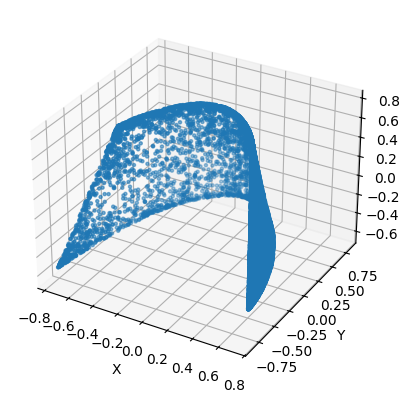

Input 10000 points, ambient dimension: 10, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.03158303759904781, 0.6731330703339535]
1.038882240848182 0.31509605522293643 1.6875888111379997
0.5944875537221137


In [22]:
t, m = t_max, 10

F = metric.eigenmap_t(t = t, m = m)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(F[:, 0], F[:, 1], F[:, 2], s=5)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.show()


embedding = LearnMetric(F, 2)
embedding.tangent_space(k = 100, degree = 2)

# manifolds with boundary
H = embedding.distortion(L = metric.L.as_nparray(), radius=r, indices=inner)

# manifolds without boundary
# H = embedding.distortion(L = metric.L.as_nparray(), radius=r)

emb_rmetric = np.sqrt(np.linalg.svdvals(H))
emb_err = np.max(np.abs(emb_rmetric - 1), axis=1)


print(np.mean(emb_rmetric), np.min(emb_rmetric), np.max(emb_rmetric))
print(np.max(np.abs(1-emb_rmetric/rmetric)))


# Results

## Sphere

In [2]:
np.random.seed(1)
X = sample_sphere(10000,3)
metric = LearnMetric(X, 2)
metric.setPara(k=100,degree=6)

eps, r = 0.5197955632416278, 1.5784418699481049
H = metric.distortion(epsilon = eps, radius = r)
rmetric = np.sqrt(np.linalg.svdvals(H))

print(rmetric)
print(np.mean(rmetric), np.min(rmetric), np.max(rmetric))

now = datetime.datetime.now()
print(now)

Input 10000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 6
  Neighbors Radius = [0.1666358291781393, 0.23224777205834338]
[[1.00198942 0.99448042]
 [1.01122163 0.99451177]
 [0.99745741 0.99489805]
 ...
 [1.00140308 0.99576407]
 [1.00511464 1.00362391]
 [1.00658125 0.99899667]]
1.0011886283514326 0.9884135586511111 1.0124850106355188
2026-05-06 23:52:19.923149


In [3]:
reachEst = ReachEstimator(X, 2)
reachEst.setPara(k = 100, degree = 6)
reach = reachEst.compute_reach()
print(reach)
now = datetime.datetime.now()
print(now)

Input 10000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 6
  Neighbors Radius = [0.1666358291781393, 0.23224777205834338]
(np.float64(0.9999962837593155), np.int64(463))
2026-05-06 23:52:37.159475


In [ ]:
t, m = 0.3360016795178129, 3

metric._laplacian_eigenmap_without_t(L=metric.L, epsilon=eps, radius=r, m=30)
# np.savez("S2-10000-30.npz", vec=metric.vecs, val=metric.vals)

# S2 = np.load("S2-10000-30.npz")
# metric.vecs = S2["vec"]
# metric.vals = S2["val"]

F = metric.eigenmap_t(t=t, m=m)

embedding = LearnMetric(F, 2)
embedding.setPara(k=100, degree=2)
H = embedding.distortion(L = metric.L.as_nparray(), radius = r)
rmetric = np.sqrt(np.linalg.svdvals(H))
print(rmetric)
print(np.mean(rmetric), np.min(rmetric), np.max(rmetric))

now = datetime.datetime.now()
print(now)

Input 10000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.16390537812661596, 0.2339964252887638]
[[1.00138055 0.98760576]
 [1.01566298 0.98659334]
 [0.99426089 0.99130077]
 ...
 [1.00100513 0.98845351]
 [1.00499974 1.00361945]
 [1.01255108 0.99361828]]
0.999228733464433 0.9796733442576079 1.0203004537716471
2026-05-06 23:57:35.622456


In [6]:
reachEst = ReachEstimator(F, 2)
reachEst.setPara(k = 2000, degree = 4)
reach = reachEst.compute_reach()
print(reach)

now = datetime.datetime.now()
print(now)

Input 10000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 2000
  degree = 4
  Neighbors Radius = [0.8666766577788112, 0.9179740679650291]
(np.float64(0.9440527744847519), (np.int64(3734), np.int64(9246)))
2026-05-06 23:58:14.085901


## Swiss Roll

[ 1.97668622 10.50189928  0.12408868]
[6.6367939  6.09837382 6.96693701]
Input 10000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 6
  Neighbors Radius = [0.2607819415116237, 0.8689559542750741]
9083
0.04782797497070328 0.002331682429800752 0.10852165118529267


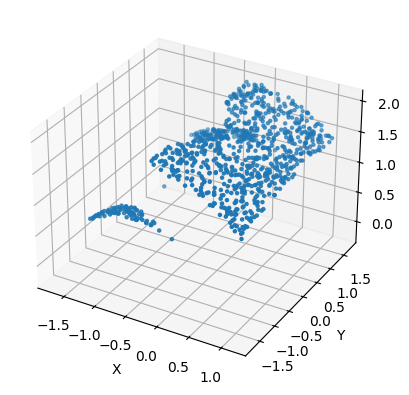

In [ ]:
np.random.seed(1)
small_coord_sys, full_coord_sys = sample_manifold(swiss_roll())
small_coord_sys.generate_data(num_samples=10000)
X = small_coord_sys.data.amb_pts
scaler = StandardScaler()
X = scaler.fit_transform(X)

print(scaler.mean_)
print(scaler.scale_)

inner = np.abs(small_coord_sys.data.coord_pts).max(axis=1) < 0.8

eps, r = 0.9161115190557412, 2.689214709900272

metric = LearnMetric(X, 2)
metric.setPara(k = 100, degree = 6)
H = metric.distortion(epsilon = eps, radius = r)
rmetric = np.sqrt(np.linalg.svdvals(H))
err = np.max(np.abs(rmetric - 1), axis=1)

good_idx = err < 0.1
print(sum(good_idx))

print(np.mean(err[inner]), np.min(err[inner]), np.max(err[inner]))

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[~good_idx, 0], X[~good_idx, 1], X[~good_idx, 2], s=5)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.show()

In [ ]:
reachEst = ReachEstimator(X, 2)
reach = reachEst.compute_reach(k = 100, degree = 6)
print(reach)

Input 10000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 6
  Neighbors Radius = [0.2607819415116237, 0.8689559542750741]
(np.float64(0.4468273871376648), (np.int64(6446), np.int64(7062)))


Input 10000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.23008082775706287, 0.7001125747605548]
0.15828227839784614
0.09330670898974625


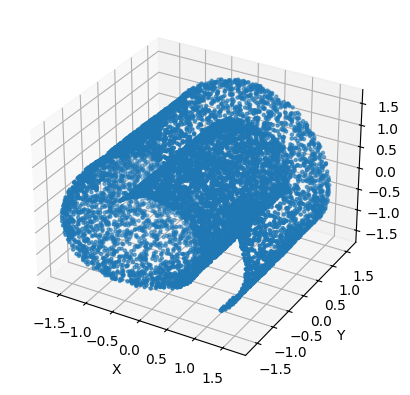

In [ ]:
t, m = 1.880059767768491, 3

# metric._laplacian_eigenmap_without_t(L = metric.L, epsilon = eps, m = 30)
# np.savez("swiss-10000-30.npz", vec=metric.vecs, val=metric.vals)

# swiss = np.load("swiss-10000-30.npz")
# metric.vecs = swiss["vec"]
# metric.vals = swiss["val"]

F = metric.eigenmap_t(t=t, m=m)

embedding = LearnMetric(F, 2)
embedding.setPara(k=100, degree=2)
H = embedding.distortion(L = metric.L.as_nparray(), radius=r)
emb_rmetric = np.sqrt(np.linalg.svdvals(H))
err_emb = np.max(np.abs(emb_rmetric - 1), axis=1)

print(np.max(err_emb[inner]))
print(np.max(np.abs(1-(emb_rmetric/rmetric)[inner])))

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(F[:, 0], F[:, 1], F[:, 2], s=5)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.show()

In [ ]:
reachEst = ReachEstimator(F, 2)
reach = reachEst.compute_reach(k = 100, degree = 2)
print(reach)

Input 10000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.23008082775706287, 0.7001125747605548]
(np.float64(0.34590021811453336), (np.int64(3350), np.int64(932)))


## Torus

In [ ]:
np.random.seed(123)
small_coord_sys, full_coord_sys = sample_manifold(torus(R=3, r=1.5))
small_coord_sys.generate_data(num_samples=10000)
X = small_coord_sys.data.amb_pts
scaler = StandardScaler()
X = scaler.fit_transform(X)

print(scaler.mean_)
print(scaler.scale_)

eps, r = 0.9190320396479403, 2.811817019225481

metric = LearnMetric(X, 2)
metric.tangent_space(k = 100, degree = 6)
H = metric.distortion(epsilon = eps, radius = r)
rmetric = np.sqrt(np.linalg.svdvals(H))

print(rmetric)
print(np.mean(rmetric), np.min(rmetric), np.max(rmetric))

[ 0.05008898  0.00424899 -0.03533768]
[2.24173186 2.24683467 1.06404622]
Input 10000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 6
  Neighbors Radius = [0.28175757480751634, 0.6835140142763657]
[[0.9631524  0.95037842]
 [0.93653056 0.93131492]
 [0.96351397 0.93678882]
 ...
 [0.9461361  0.87269717]
 [1.05973067 1.02798827]
 [1.04720271 1.0067791 ]]
0.993508501756222 0.8435562396253424 1.1556301441676182


In [ ]:
reachEst = ReachEstimator(X, 2)
reach = reachEst.compute_reach(k = 50, degree = 6)
print(reach)

Input 10000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 50
  degree = 6
  Neighbors Radius = [0.17861918995612258, 0.5089036017660483]
(np.float64(0.31616094747240026), np.int64(1644))


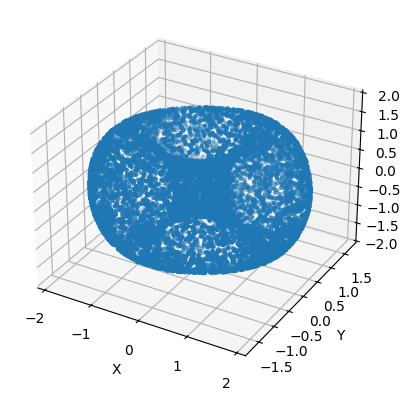

Input 10000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.23805541471392438, 0.6574673158465298]
0.15161375446895445 0.08276080839737832 0.250355180682287
0.15615088593301518


In [ ]:
t, m = 1.788110352114892, 3

# metric._laplacian_eigenmap_without_t(L=metric.L, epsilon=eps, radius=r, m=30)
# np.savez("torus-10000-30.npz", vec=metric.vecs, val=metric.vals)

# torusdata = np.load("torus-10000-30.npz")
# metric.vecs = torusdata["vec"]
# metric.vals = torusdata["val"]

F = metric.eigenmap_t(t=t, m=m)


fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(F[:, 0], F[:, 1], F[:, 2], s=5)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.show()

embedding = LearnMetric(F, 2)
embedding.tangent_space(k = 100, degree = 2)
H = embedding.distortion(L = metric.L.as_nparray(), radius=r)
emb_rmetric = np.sqrt(np.linalg.svdvals(H))
err_emb = np.max(np.abs(emb_rmetric - 1), axis=1)

print(np.mean(err_emb), np.min(err_emb), np.max(err_emb))
print(np.max(np.abs(1-(emb_rmetric/rmetric))))

In [ ]:
reachEst = ReachEstimator(F, 2)
reach = reachEst.compute_reach(k = 120, degree = 2)
print(reach)

Input 10000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 120
  degree = 2
  Neighbors Radius = [0.26397156406515365, 0.7030306385283948]
(np.float64(0.17313979206400906), np.int64(8701))


## Random Manifold

### M1

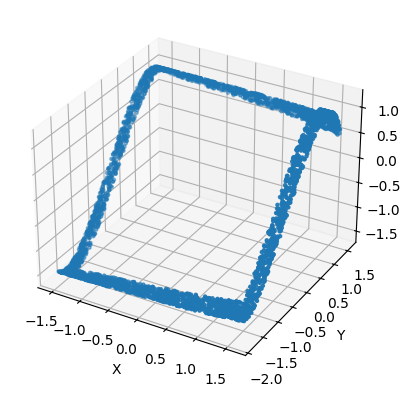

Input 10000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 6
  Neighbors Radius = [0.11488019024211607, 0.34205042415327536]
6134


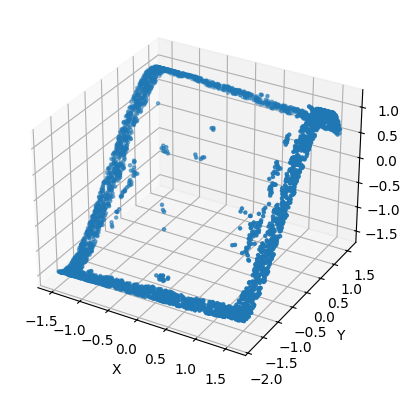

[[1.07311408 1.00637309]
 [1.04250094 1.01435239]
 [1.01769832 0.9817513 ]
 ...
 [1.03594926 0.98619987]
 [1.01883052 0.98717362]
 [0.9970632  0.918478  ]]
1.0079231260182262 0.7687849625664631 1.176415105766808
0.05893991103813593


In [2]:
np.random.seed(1)
small_coord_sys, full_coord_sys = sample_m1()
small_coord_sys.generate_data(num_samples=10000)
X = small_coord_sys.data.amb_pts
inner = np.max(np.abs(small_coord_sys.data.coord_pts), axis=1) < 0.8
X = StandardScaler().fit_transform(X)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[~inner, 0], X[~inner, 1], X[~inner, 2], s=5)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.show()

metric = LearnMetric(X, 2)
metric.tangent_space(k = 100, degree = 6)

eps, r = 0.1718350362125734, 0.39380657293758103


H = metric.distortion(epsilon = eps, radius = r)
rmetric = np.sqrt(np.linalg.svdvals(H))
err = np.max(np.abs(rmetric - 1), axis=1)

good_idx = err <= 0.1
print(sum(good_idx))

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[~good_idx, 0], X[~good_idx, 1], X[~good_idx, 2], s=5)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.show()

print(rmetric[inner,:])
print(np.mean(rmetric[inner,:]), np.min(rmetric[inner,:]), np.max(rmetric[inner,:]))
print(np.mean(err[inner]))

In [ ]:
# m1data = np.load("m1-10000-100.npz")
# metric.vecs = m1data["vec"]
# metric.vals = m1data["val"]

In [ ]:
t, m = 0.11552785762896797 , 10

F = metric.eigenmap_t(t=t, m=m)
embedding = LearnMetric(F, 2)
embedding.setPara(k=100, degree=2)
H = embedding.distortion(L = metric.L.as_nparray(), radius=r, indices = inner)
emb_rmetric = np.sqrt(np.linalg.svdvals(H))

print(np.max(np.abs(1-(emb_rmetric/rmetric[inner]))))

Input 10000 points, ambient dimension: 10, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.03576754294032231, 0.32645442005149217]
0.5528022159357989


In [ ]:
t, m = 0.0567003276847082, 20

F = metric.eigenmap_t(t=t, m=m)
embedding = LearnMetric(F, 2)
embedding.setPara(k=100, degree=2)
H = embedding.distortion(L = metric.L.as_nparray(), radius=r, indices = inner)
emb_rmetric = np.sqrt(np.linalg.svdvals(H))

print(np.max(np.abs(1-(emb_rmetric/rmetric[inner]))))

Input 10000 points, ambient dimension: 20, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.04485461739023969, 0.30510917558431494]
0.42724692644524587


In [ ]:
t, m = 0.04085590279974119, 30

F = metric.eigenmap_t(t=t, m=m)
embedding = LearnMetric(F, 2)
embedding.setPara(k=100, degree=2)
H = embedding.distortion(L = metric.L.as_nparray(), radius=r, indices = inner)
emb_rmetric = np.sqrt(np.linalg.svdvals(H))

print(np.max(np.abs(1-(emb_rmetric/rmetric[inner]))))

Input 10000 points, ambient dimension: 30, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.061115610367493446, 0.32602748213674165]
0.35301342744879904


In [ ]:
t, m = 0.03339561588348327 , 40

F = metric.eigenmap_t(t=t, m=m)
embedding = LearnMetric(F, 2)
embedding.setPara(k=100, degree=2)
H = embedding.distortion(L = metric.L.as_nparray(), radius=r, indices = inner)
emb_rmetric = np.sqrt(np.linalg.svdvals(H))

print(np.max(np.abs(1-(emb_rmetric/rmetric[inner]))))

Input 10000 points, ambient dimension: 40, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.07689349903855756, 0.36038391228403005]
0.3275536483896042


### M2

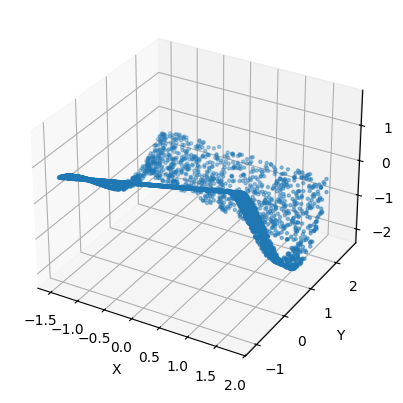

Input 10000 points, ambient dimension: 4, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 6
  Neighbors Radius = [0.09888825248594041, 0.9688208403410233]
5231


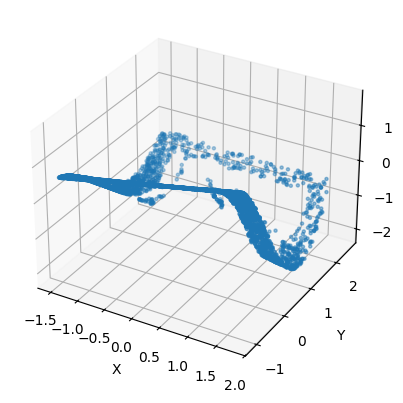

[[1.03674044 0.92847322]
 [1.07746879 0.80649681]
 [1.02241631 0.98023612]
 ...
 [1.03469697 1.00556514]
 [1.03943751 0.98057598]
 [1.00892069 0.96211115]]
0.9853101783197311 0.6714295335111554 1.1521978587663264
0.08217329577273176


In [6]:
np.random.seed(1)
small_coord_sys, full_coord_sys = sample_m2()
small_coord_sys.generate_data(num_samples=10000)
X = small_coord_sys.data.amb_pts
inner = np.max(np.abs(small_coord_sys.data.coord_pts), axis=1) < 0.8
X = StandardScaler().fit_transform(X)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[~inner, 0], X[~inner, 1], X[~inner, 2], s=5)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.show()

metric = LearnMetric(X, 2)
metric.tangent_space(k = 100, degree = 6)

eps, r = 0.3006881815926802, 0.6788941049743745

H = metric.distortion(epsilon = eps, radius = r)
rmetric = np.sqrt(np.linalg.svdvals(H))
err = np.max(np.abs(rmetric - 1), axis=1)

good_idx = err <= 0.1
print(sum(good_idx))

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[~good_idx, 0], X[~good_idx, 1], X[~good_idx, 2], s=5)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.show()

print(rmetric[inner,:])
print(np.mean(rmetric[inner,:]), np.min(rmetric[inner,:]), np.max(rmetric[inner,:]))
print(np.mean(err[inner]))

In [8]:
m2data = np.load("m2-10000-100.npz")
metric.vecs = m2data["vec"]
metric.vals = m2data["val"]

In [ ]:
t, m = 0.26356267948072765, 10

F = metric.eigenmap_t(t=t, m=m)
embedding = LearnMetric(F, 2)
embedding.setPara(k=100, degree=2)
H = embedding.distortion(L = metric.L.as_nparray(), radius=r, indices = inner)
emb_rmetric = np.sqrt(np.linalg.svdvals(H))

print(np.max(np.abs(1-(emb_rmetric/rmetric[inner]))))

Input 10000 points, ambient dimension: 10, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.03158315833815456, 0.6731356800322187]
0.5944858521652695


In [ ]:
t, m = 0.1287430629926426, 20

F = metric.eigenmap_t(t=t, m=m)
embedding = LearnMetric(F, 2)
embedding.setPara(k=100, degree=2)
H = embedding.distortion(L = metric.L.as_nparray(), radius=r, indices = inner)
emb_rmetric = np.sqrt(np.linalg.svdvals(H))

print(np.max(np.abs(1-(emb_rmetric/rmetric[inner]))))

Input 10000 points, ambient dimension: 20, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.040003316630957166, 0.945918100296314]
0.3909044920956133


In [ ]:
t, m = 0.09788461158847671, 30

F = metric.eigenmap_t(t=t, m=m)
embedding = LearnMetric(F, 2)
embedding.setPara(k=100, degree=2)
H = embedding.distortion(L = metric.L.as_nparray(), radius=r, indices = inner)
emb_rmetric = np.sqrt(np.linalg.svdvals(H))

print(np.max(np.abs(1-(emb_rmetric/rmetric[inner]))))

Input 10000 points, ambient dimension: 30, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.0564577926610966, 1.0764717253486422]
0.2797462735187115


In [ ]:
t, m = 0.07791161351417429, 40

F = metric.eigenmap_t(t=t, m=m)
embedding = LearnMetric(F, 2)
embedding.setPara(k=100, degree=2)
H = embedding.distortion(L = metric.L.as_nparray(), radius=r, indices = inner)
emb_rmetric = np.sqrt(np.linalg.svdvals(H))

print(np.max(np.abs(1-(emb_rmetric/rmetric[inner]))))

Input 10000 points, ambient dimension: 40, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 2
  Neighbors Radius = [0.06704397997242578, 1.1826419310005003]
0.244019473296897


# New Experiments


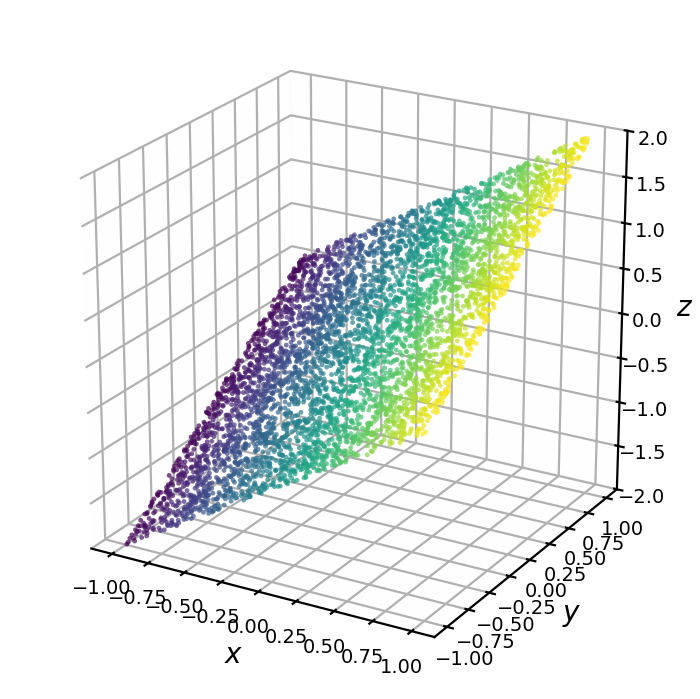

In [14]:
np.random.seed(1)
n = 5000
x = np.random.uniform(-1, 1, n)
y = np.random.uniform(-1, 1, n)
z = x+y
X = np.column_stack([x, y, z])

color = x

fig = plt.figure(figsize=(4.2, 3.6), dpi=200)
ax = fig.add_subplot(111, projection="3d")
ax.scatter(
    X[:, 0], X[:, 1], X[:, 2],
    c=color, cmap="viridis",
    s=3, alpha=0.7, linewidths=0, rasterized=True,
)
ax.set_xlabel("$x$", labelpad=-6)
ax.set_ylabel("$y$", labelpad=-6)
ax.set_zlabel("$z$", labelpad=-6)
ax.set_zlim(-2, 2)
ax.set_box_aspect((1, 1, 1))
ax.view_init(elev=22, azim=-60)
ax.tick_params(pad=-2, labelsize=7)
ax.grid(True, linewidth=0.3, alpha=0.4)
ax.xaxis.pane.set_alpha(0.03)
ax.yaxis.pane.set_alpha(0.03)
ax.zaxis.pane.set_alpha(0.03)
fig.tight_layout()
plt.show()


In [4]:
metric = LearnMetric(X, 2)
metric._laplacian_eigenmap_without_t(m=3)

Input 5000 points, ambient dimension: 3, intrinsic dimension: 2


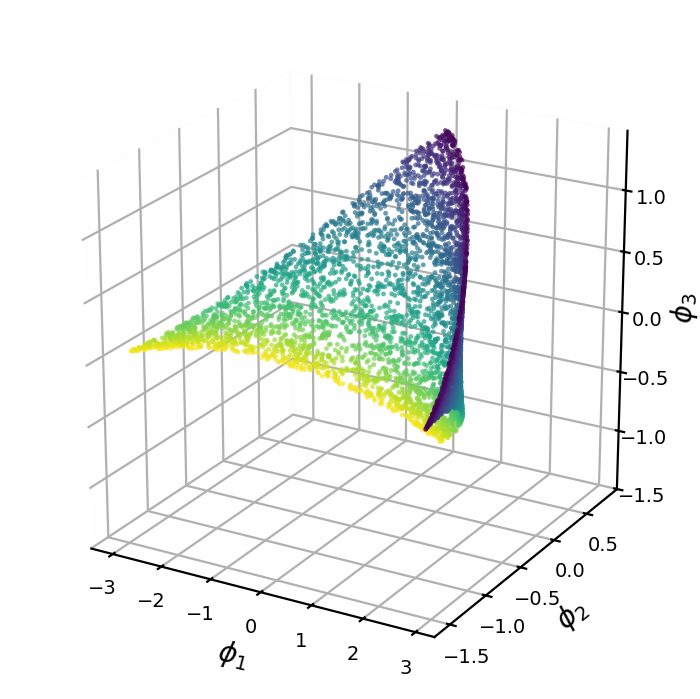

In [ ]:
F = metric.eigenmap_t(t=1, m=3)

fig = plt.figure(figsize=(4.2, 3.6), dpi=200)
ax = fig.add_subplot(111, projection="3d")
ax.scatter(
    F[:, 0], F[:, 1], F[:, 2],
    c=color, cmap="viridis",
    s=3, alpha=0.7, linewidths=0, rasterized=True,
)
ax.set_xlabel("$\\phi_1$", labelpad=-6)
ax.set_ylabel("$\\phi_2$", labelpad=-6)
ax.set_zlabel("$\\phi_3$", labelpad=-6)
ax.set_box_aspect((1, 1, 1))
ax.view_init(elev=22, azim=-60)
ax.tick_params(pad=-2, labelsize=7)
ax.grid(True, linewidth=0.3, alpha=0.4)
ax.xaxis.pane.set_alpha(0.03)
ax.yaxis.pane.set_alpha(0.03)
ax.zaxis.pane.set_alpha(0.03)
fig.tight_layout()
plt.show()


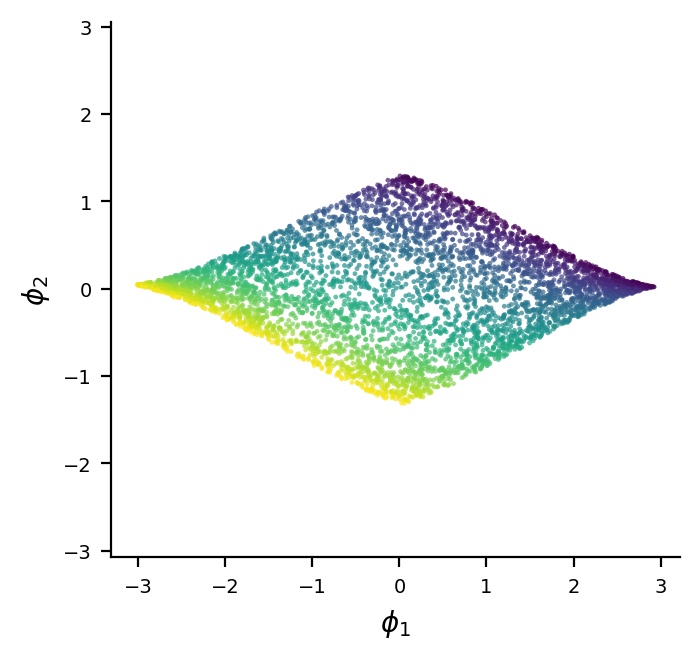

In [ ]:
fig, ax = plt.subplots(figsize=(3.6, 3.4), dpi=200)
ax.scatter(
    F[:, 0], F[:, 2],
    c=color, cmap="viridis",
    s=3, alpha=0.7, linewidths=0, rasterized=True,
)
ax.set_xlabel("$\\phi_1$")
ax.set_ylabel("$\\phi_2$")
ax.set_aspect("equal", adjustable="datalim")
ax.tick_params(labelsize=7)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
plt.show()


/var/folders/fg/2y9yw_kn1cl7l1jspn6scz000000gp/T/ipykernel_52075/3535783869.py:36: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


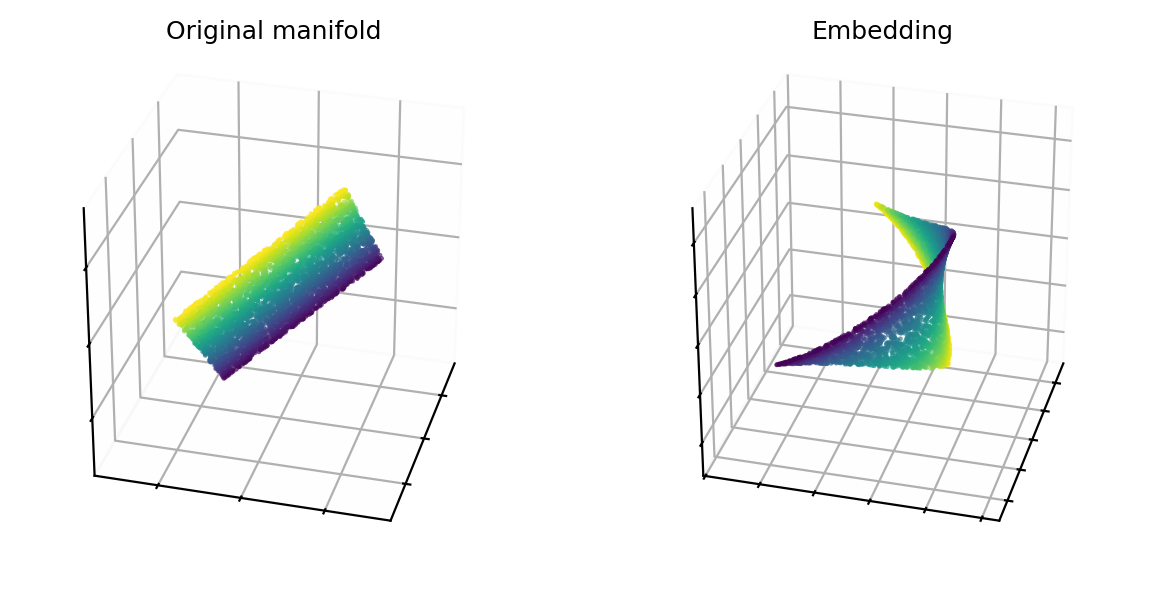

In [ ]:
def style_3d(ax, pts):

    mins = pts.min(axis=0)
    maxs = pts.max(axis=0)
    centers = (mins + maxs) / 2
    half = (maxs - mins).max() / 2 * 0.9
    ax.set_xlim(centers[0] - half, centers[0] + half)
    ax.set_ylim(centers[1] - half, centers[1] + half)
    ax.set_zlim(centers[2] - half, centers[2] + half)
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=30, azim=15)

    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
    ax.tick_params(length=0)
    ax.grid(True, linewidth=0.3, alpha=0.5)
    for pane in (ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane):
        pane.set_alpha(0.04)
        pane.set_edgecolor("0.7")

fig = plt.figure(figsize=(7.2, 3.6), dpi=200)


ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.scatter(X[:, 0], X[:, 1], X[:, 2],
            c=color, cmap="viridis", s=3, alpha=0.7, linewidths=0, rasterized=True)
style_3d(ax1, X)
ax1.set_title("Original manifold", fontsize=9, pad=0)


ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.scatter(F[:, 0], F[:, 1], F[:, 2],
            c=color, cmap="viridis", s=3, alpha=0.7, linewidths=0, rasterized=True)
style_3d(ax2, F)
ax2.set_title("Embedding", fontsize=9, pad=0)

fig.tight_layout()
plt.show()


## Tendency with n

In [8]:
np.random.seed(123)
n = 10000
X = sample_sphere(n,3)
metric = LearnMetric(X, 2)
metric.setPara(k=100,degree=6)
eps, r = 0.5197955632416278, 1.5784418699481049
H = metric.distortion(epsilon = eps, radius = r)
rmetric = np.sqrt(np.linalg.svdvals(H))
print(rmetric)
print(np.mean(rmetric), np.min(rmetric), np.max(rmetric))
print(np.max(np.abs(rmetric-1)))


Input 10000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 6
  Neighbors Radius = [0.153667678207718, 0.2320471970332006]
[[1.00469674 1.00264553]
 [1.00165043 0.99613054]
 [1.00426683 0.99396972]
 ...
 [1.01501627 0.98543102]
 [1.01523107 0.99885813]
 [1.00064412 0.99677857]]
1.001084215046854 0.9834059946124636 1.0177233150818292
0.017723315081829227


In [3]:
n_list = [500, 1000, 2000, 5000, 10000]
n_repeat = 3
eps, r = 0.52, 2.0

mean_err = np.zeros((len(n_list), n_repeat))
max_err  = np.zeros((len(n_list), n_repeat))

for i, n in enumerate(n_list):
    for j in range(n_repeat):
        np.random.seed(100 * i + j)
        X = sample_sphere(n, 3)
        metric = LearnMetric(X, 2)
        metric.setPara(k=100, degree=6)

        H = metric.distortion(epsilon=eps, radius=r)
        rm = np.sqrt(np.linalg.svdvals(H))
        err = np.abs(rm - 1.0)
        mean_err[i, j] = np.mean(err)
        max_err[i, j]  = np.max(err)
        print(f"n={n:6d} rep={j} mean_err={mean_err[i, j]:.4f} "
              f"max_err={max_err[i, j]:.4f}")


Input 500 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 6
  Neighbors Radius = [0.8189722793621749, 0.9868335712631371]
n=   500 rep=0 mean_err=0.0240 max_err=0.0836
Input 500 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 6
  Neighbors Radius = [0.7865989905100963, 1.007967807677929]
n=   500 rep=1 mean_err=0.0202 max_err=0.0666
Input 500 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 6
  Neighbors Radius = [0.7873067659435666, 1.009910125248415]
n=   500 rep=2 mean_err=0.0252 max_err=0.0693
Input 1000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 6
  Neighbors Radius = [0.5445728959931149, 0.7052961640001328]
n=  1000 rep=0 mean_err=0.0181 max_err=0.0531
Input 1000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  k = 100
  degree = 6
  Neighbors Radius = [0.55220592453055

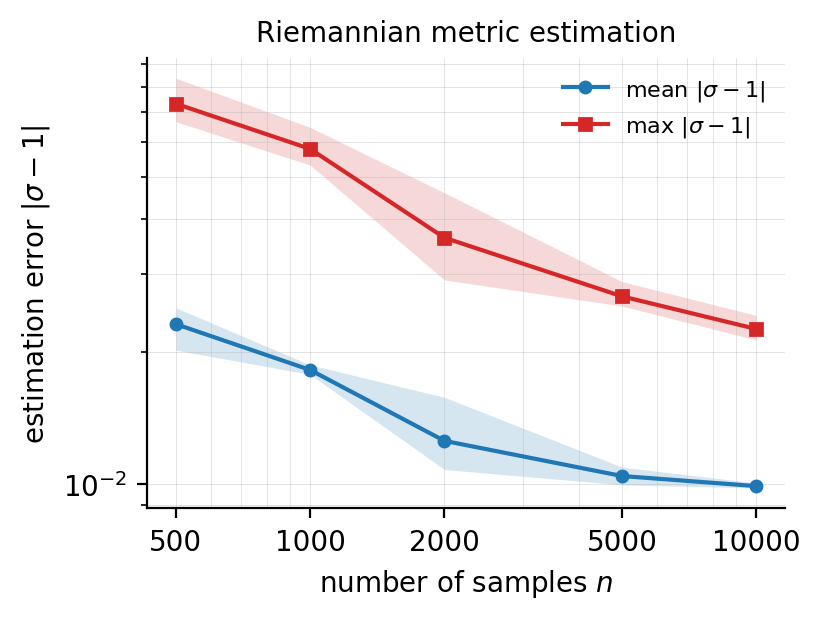

In [ ]:
n_arr = np.array(n_list)
mean_mu = mean_err.mean(axis=1)
max_mu  = max_err.mean(axis=1)
fig, ax = plt.subplots(figsize=(4.2, 3.2), dpi=200)
ax.plot(n_arr, mean_mu, "-o", ms=4, lw=1.5, color="#1f77b4",
        label=r"mean $|\sigma-1|$")
ax.fill_between(n_arr, mean_err.min(axis=1), mean_err.max(axis=1),
                color="#1f77b4", alpha=0.18, linewidth=0)
ax.plot(n_arr, max_mu, "-s", ms=4, lw=1.5, color="#d62728",
        label=r"max $|\sigma-1|$")
ax.fill_between(n_arr, max_err.min(axis=1), max_err.max(axis=1),
                color="#d62728", alpha=0.18, linewidth=0)
ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xticks(n_arr)
ax.set_xticklabels([str(v) for v in n_arr])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.tick_params(axis="x", which="minor", length=0)
ax.set_xlabel(r"number of samples $n$")
ax.set_ylabel(r"estimation error $|\sigma-1|$")
ax.set_title("Riemannian metric estimation", fontsize=10)
ax.grid(True, which="both", linewidth=0.3, alpha=0.4)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.savefig("tendency_with_n.pdf", bbox_inches="tight")
plt.show()


## Reach

In [ ]:
small_coord_sys, full_coord_sys = sample_manifold(torus(R=3, r=1.5))

small_coord_sys.generate_data(num_samples=8000)
small_coord_sys.data.visualize_pts()

X = small_coord_sys.data.amb_pts
geo = ReachEstimator(X,2)

reach, _ = geo.compute_reach(degree = 4, k = 100)

In [10]:
reach_true = 1.5
n_list_reach = [500, 1000, 2000, 5000, 10000]
n_repeat = 3

reach_est = np.full((len(n_list_reach), n_repeat), np.nan)

for i, n in enumerate(n_list_reach):
    for j in range(n_repeat):
        np.random.seed(100 * i + j)
        small_coord_sys, full_coord_sys = sample_manifold(torus(R=3, r=1.5))
        small_coord_sys.generate_data(num_samples=n)
        X = small_coord_sys.data.amb_pts
        geo = ReachEstimator(X, 2)
        reach, _ = geo.compute_reach(degree=4, k=100)
        reach_est[i, j] = reach
        print(f"n={n:6d} rep={j} reach_hat={reach:.4f}")


Input 500 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  degree = 4
  k = 100
  Neighbors Radius = [2.307163971769555, 3.3552922747000613]
n=   500 rep=0 reach_hat=0.1804
Input 500 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  degree = 4
  k = 100
  Neighbors Radius = [2.1639447966454526, 3.6070098630085905]
n=   500 rep=1 reach_hat=0.1507
Input 500 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  degree = 4
  k = 100
  Neighbors Radius = [2.2400475197854477, 3.500220284988434]
n=   500 rep=2 reach_hat=0.2112
Input 1000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  degree = 4
  k = 100
  Neighbors Radius = [1.4890476053681994, 2.8518741560797145]
n=  1000 rep=0 reach_hat=0.4046
Input 1000 points, ambient dimension: 3, intrinsic dimension: 2
Updated Parameters:
  degree = 4
  k = 100
  Neighbors Radius = [1.4706844658408278, 2.7857031576755804]
n=  1000 rep=1 reach_hat=0.2832


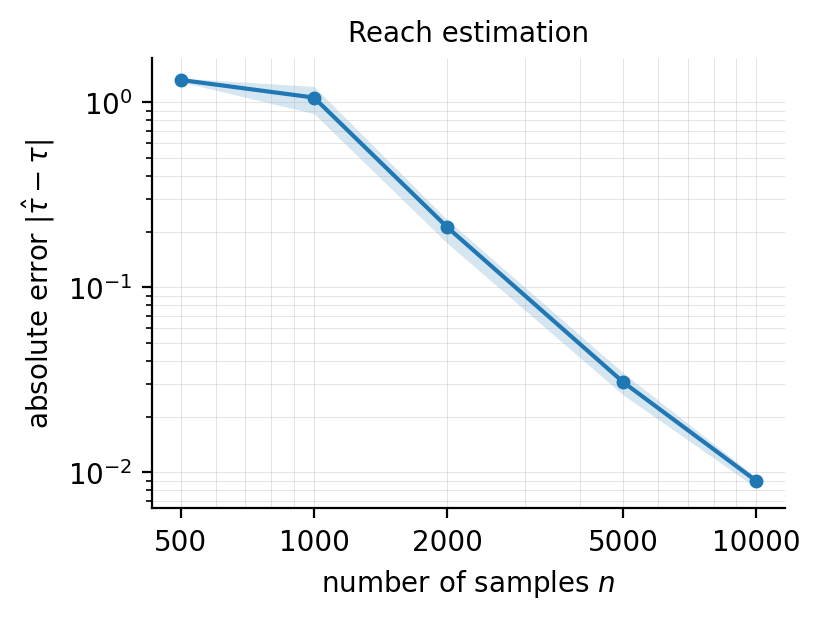

In [13]:
y = np.abs(reach_est - reach_true)
ylabel = r"absolute error $|\hat{\tau} - \tau|$"
title = "Reach estimation"
logy = True

y = np.asarray(y, dtype=float)
fig, ax = plt.subplots(figsize=(4.2, 3.2), dpi=200)
if y.ndim == 1:
    ax.plot(n_arr, y, "-o", ms=4, lw=1.5, color="#1f77b4")
else:
    mu = y.mean(axis=1)
    ax.plot(n_list_reach, mu, "-o", ms=4, lw=1.5, color="#1f77b4")
    ax.fill_between(n_list_reach, y.min(axis=1), y.max(axis=1),
                    color="#1f77b4", alpha=0.18, linewidth=0)
ax.set_xscale("log")
if logy:
    ax.set_yscale("log")

ax.set_xticks(n_list_reach)
ax.set_xticklabels([str(v) for v in n_list_reach])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.tick_params(axis="x", which="minor", length=0)
ax.set_xlabel(r"number of samples $n$")
ax.set_ylabel(ylabel)
ax.set_title(title, fontsize=10)
ax.grid(True, which="both", linewidth=0.3, alpha=0.4)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
plt.show()
